### Scans for Argon and Ne


In [15]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [16]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

solver = RE.solver0D()
solver.display() # Show default values

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


In [17]:
solver.n_imp = 1e20
solver.k = 1.7
solver.Ir0 = 1e4
solver.iDreicer = 0
solver.tmax = 7e-3
solver.display()

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.700
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1e+04
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e+20
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 0, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


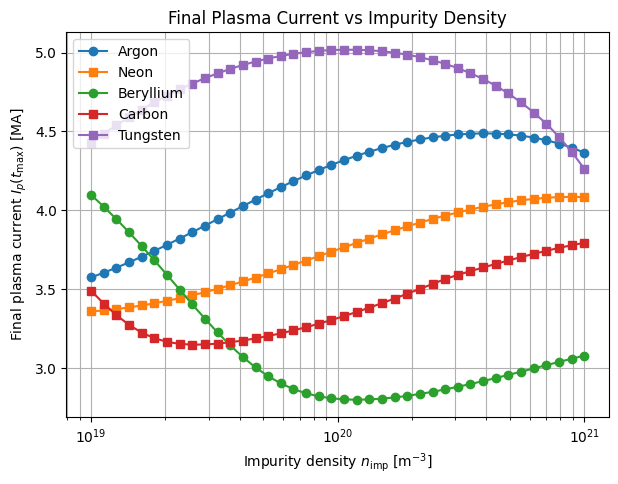

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Impurity density scan [m^-3]
n_imp_scan = np.logspace(19, 21, 40)

def run_scan(Z_imp, A_imp):
    Ipf = []

    for nimp in n_imp_scan:
        solver = solver0D()

        # Set impurity properties
        solver.Z_imp = Z_imp
        solver.A_imp = A_imp
        solver.n_imp = nimp

        solver.k = 1.7
        solver.Ir0 = 1
        solver.iDreicer = 0
        solver.tmax = 7e-3

        # Solve
        t, Ip, Ir, Wk = solver.solve()

        # Store final plasma current
        Ipf.append(Ip[-1])
    #print(Ipf)
    return np.array(Ipf)


# Run scans
Ip_Ar = run_scan(Z_imp=18, A_imp=40)  # Argon
Ip_Ne = run_scan(Z_imp=10, A_imp=20)  # Neon
Ip_Be = run_scan(Z_imp=4, A_imp=9)  # Argon
Ip_C = run_scan(Z_imp=6, A_imp=12)  # Neon
Ip_W = run_scan(Z_imp=74, A_imp=184)

# Plot
plt.figure(figsize=(7,5))
plt.semilogx(n_imp_scan, Ip_Ar/1e6, 'o-', label='Argon')
plt.semilogx(n_imp_scan, Ip_Ne/1e6, 's-', label='Neon')
plt.semilogx(n_imp_scan, Ip_Be/1e6, 'o-', label='Beryllium')
plt.semilogx(n_imp_scan, Ip_C/1e6, 's-', label='Carbon')
plt.semilogx(n_imp_scan, Ip_W/1e6, 's-', label='Tungsten')
#plt.xlim((0,8))
plt.xlabel(r'Impurity density $n_{\mathrm{imp}}$ [m$^{-3}$]')
plt.ylabel(r'Final plasma current $I_p(t_{\max})$ [MA]')
plt.grid(True, which='both')
plt.legend()
plt.title('Final Plasma Current vs Impurity Density')

plt.show()


6452685.67025368


Text(0.5, 1.0, 'Ar: n_imp=1e+19, Ip6452685.67025368')

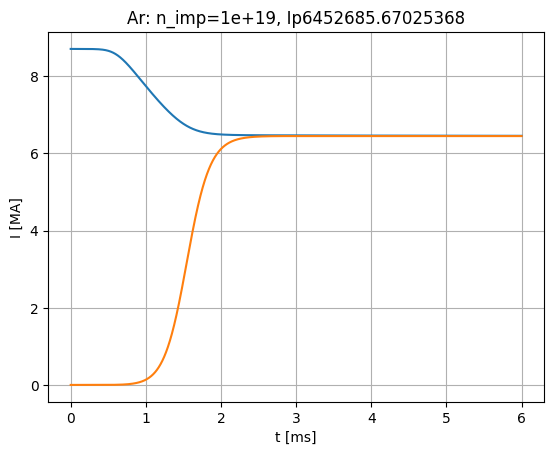

In [5]:
solver = solver0D()


solver.k = 1.7
solver.Ir0 = 1e4
solver.iDreicer = 0
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 18
solver.A_imp = 40
solver.n_imp = 1e19

# Solve
t, Ip, Ir, Wk = solver.solve()
print(Ip[-1])


plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title(f'Ar: n_imp={solver.n_imp}, Ip{Ip[-1]}')

6547465.4268574985


Text(0.5, 1.0, 'Ne')

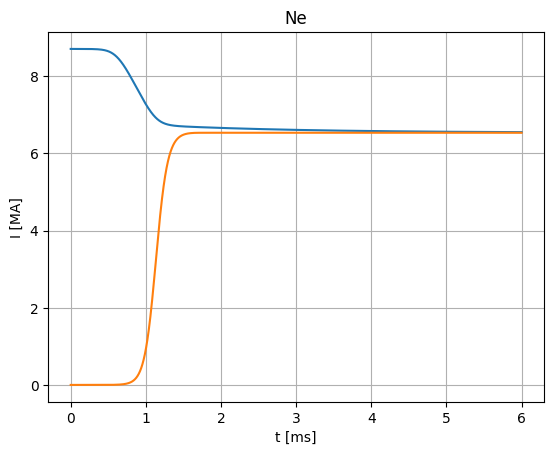

In [6]:
solver = solver0D()


solver.k = 1.7
solver.Ir0 = 1e4
solver.iDreicer = 0
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e21

# Solve
t, Ip, Ir, Wk = solver.solve()
print(Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('Ne')

222890.3564075883


Text(0.5, 1.0, 'C')

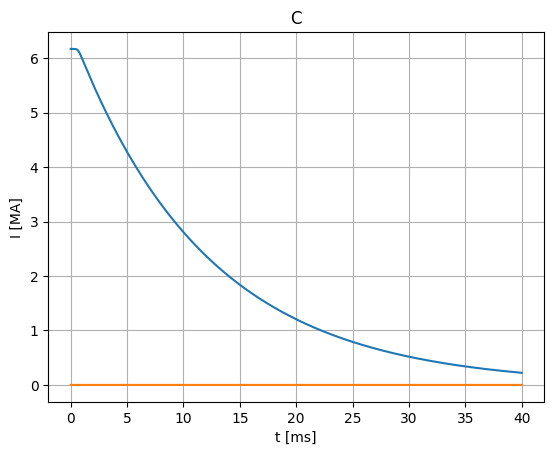

In [7]:
solver = solver0D()

# Adjusting for JET parameters

solver.R0 = 2.96
solver.a = 1.2
solver.k = 1.6
solver.Btor = 3.45

#solver.k = 1.7
solver.I0 = 6.17e6
solver.iDreicer = 1
solver.tmax = 40e-3

solver.Tf = 10

# Set impurity properties
solver.Z_imp = 6
solver.A_imp = 12
solver.n_imp = 3e19

solver.iAvalanche = 1

# Solve
t, Ip, Ir, Wk = solver.solve()
print(Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('C')

740812.1701868816


Text(0.5, 1.0, 'Be')

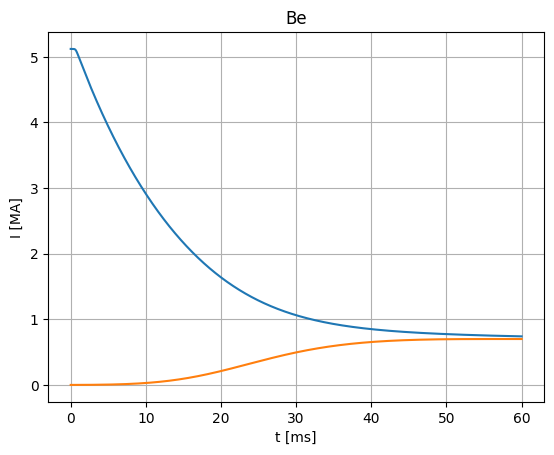

In [8]:
solver = solver0D()

# Adjusting for JET parameters

solver.R0 = 2.96
solver.a = 1.2
solver.k = 1.6
solver.Btor = 3.45

#solver.k = 1.7
solver.I0 = 5.12e6
solver.Ir0 = 1000
solver.iDreicer = 1
solver.tmax = 60e-3

solver.Tf = 10

# Set impurity properties
solver.Z_imp = 4
solver.A_imp = 8
solver.n_imp = 3e19

# Solve
t, Ip, Ir, Wk = solver.solve()
print(Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('Be')